p=0.5: max relative error = 3.08e-135
p=1: max relative error = 8.11e-147
p=2: max relative error = 2.73e-149


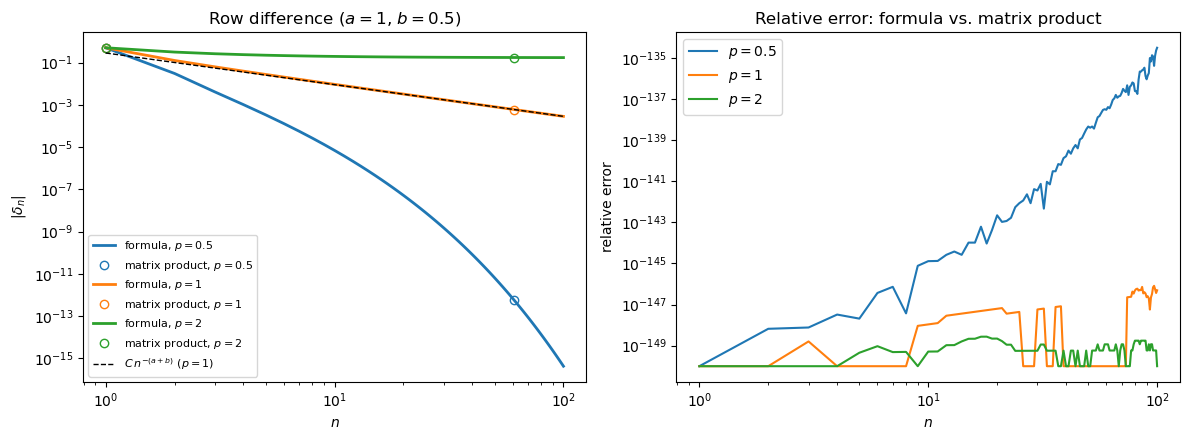

In [17]:
#Want to compare the closed-form row difference with a direct matrix-product computation.
 
#Formula:  delta_n = prod_{t=1}^n (1 - (a+b)/t^p)
#Computed: delta_n = Q_n[0,0] - Q_n[1,0],  where Q_n = P_1 P_2 ... P_n
 
#delta_n can shrink below 1e-60, while x_n - y_n in double precision cannot resolve anything below ~1e-16 (catastrophic cancellation). 
#Both quantities are therefore computed with 150-digit decimal arithmetic (standard library).

from decimal import Decimal as D, getcontext
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import warnings
warnings.filterwarnings("ignore", category=matplotlib.MatplotlibDeprecationWarning) #Not using matplotlib 3.12

getcontext().prec = 150

a, b = D(1), D("0.5")      # transition parameters
N = 100                    # number of steps
ps = ["0.5", "1", "2"]     # values of p


def delta_matrix(p, N):
    """Actual matrix product."""
    p = D(p)
    (q11, q12), (q21, q22) = (D(1), D(0)), (D(0), D(1))   # Q_0 = I
    out = []
    for t in range(1, N + 1):
        r = D(t) ** (-p)
        A, B = a * r, b * r
        q11, q12 = q11 * (1 - A) + q12 * B, q11 * A + q12 * (1 - B)
        q21, q22 = q21 * (1 - A) + q22 * B, q21 * A + q22 * (1 - B)
        out.append(q11 - q21)
    return out


def delta_formula(p, N):
    """delta_n from the product formula."""
    p, prod, out = D(p), D(1), []
    for t in range(1, N + 1):
        prod *= 1 - (a + b) / D(t) ** p
        out.append(prod)
    return out


n = np.arange(1, N + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

for p, color in zip(ps, ["tab:blue", "tab:orange", "tab:green"]):
    form, comp = delta_formula(p, N), delta_matrix(p, N)
    rel = [abs(f - c) / abs(f) for f, c in zip(form, comp)]
    ax1.plot(n, [float(abs(v)) for v in form], color=color, lw=2,
             label=f"formula, $p={p}$")
    ax1.plot(n[::60], [float(abs(v)) for v in comp][::60], "o", color=color,
             mfc="none", label=f"matrix product, $p={p}$")
    ax2.plot(n, [max(float(v), 1e-150) for v in rel], color=color,
             label=f"$p={p}$")
    print(f"p={p}: max relative error = {float(max(rel)):.2e}")

c = float(a + b)
C = float(abs(delta_formula("1", N)[-1])) * N ** c
ax1.plot(n, C * n ** (-c), "k--", lw=1, label=r"$C\,n^{-(a+b)}$ ($p=1$)")

ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel("$n$"); ax1.set_ylabel(r"$|\delta_n|$")
ax1.set_title(f"Row difference ($a={a}$, $b={b}$)")
ax1.legend(fontsize=8)

ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("$n$"); ax2.set_ylabel("relative error")
ax2.set_title("Relative error: formula vs. matrix product")
ax2.legend()

plt.tight_layout()
plt.savefig("comparison.png", dpi=200)
plt.show()